## Install required dependancies.

In [1]:
!pip install copernicusmarine cdsapi xarray netCDF4

## Searched through exiting datasets to find matching dataset for subsurface temp

In [9]:
import subprocess

# Search for ACTIVE Mediterranean multi-year/reanalysis temperature datasets
print("🔍 Searching for ACTIVE Mediterranean temperature datasets...\n")

# Try different search patterns
searches = [
    ["copernicusmarine", "describe", "--contains", "med", "--contains", "multiyear", "--contains", "phy"],
    ["copernicusmarine", "describe", "--contains", "mediterranean", "--contains", "reanalysis"],
    ["copernicusmarine", "describe", "--contains", "MEDSEA_MULTIYEAR_PHY"],
]

for search_cmd in searches:
    print(f"\n{'='*70}")
    print(f"Search: {' '.join(search_cmd[2:])}")
    print('='*70)
    
    result = subprocess.run(search_cmd, capture_output=True, text=True)
    
    if "dataset_id" in result.stdout:
        # Extract and print dataset IDs
        for line in result.stdout.split('\n'):
            if 'dataset_id' in line and 'tem' in line.lower():
                print(f" {line.strip()}")
    else:
        print(" No results")

🔍 Searching for ACTIVE Mediterranean temperature datasets...


Search: --contains med --contains multiyear --contains phy
 "dataset_id": "arctic_omi_tempsal_fwc",
 "dataset_id": "cmems_mod_blk_phy-tem_anfc_mrm-500m_P1D-m",
 "dataset_id": "cmems_mod_blk_phy-tem_anfc_mrm-500m_PT1H-i",
 "dataset_id": "cmems_mod_blk_phy-temp_anfc_2.5km_P1D-m",
 "dataset_id": "cmems_mod_blk_phy-temp_anfc_2.5km_P1M-m",
 "dataset_id": "cmems_mod_blk_phy-temp_anfc_2.5km_PT1H-m",
 "dataset_id": "cmems_mod_blk_phy-temp_my_2.5km-climatology_P1M-m",
 "dataset_id": "cmems_mod_blk_phy-temp_my_2.5km_P1D-m",
 "dataset_id": "cmems_mod_blk_phy-temp_my_2.5km_P1M-m",
 "dataset_id": "cmems_mod_blk_phy-temp_my_2.5km_P1Y-m",
 "dataset_id": "blksea_omi_tempsal_extreme_var_temp_mean_and_anomaly",
 "dataset_id": "blksea_omi_tempsal_sst_area_averaged_anomalies",
 "dataset_id": "blksea_omi_tempsal_sst_trend",
 "dataset_id": "global_omi_tempsal_tyz_trend",
 "dataset_id": "global_omi_tempsal_sst_area_averaged_anomalies",
 "dataset_

## Login to copernicus to access the data

In [ ]:

import copernicusmarine

# Try the correct login syntax
try:
    copernicusmarine.login(
        username="",
        password="",
    )
    print("Logged in successfully!")
    print("Credentials are now saved!")
    
except Exception as e:
    print(f" Error: {e}")

## Initalise required variables and set up folders

In [69]:
import copernicusmarine
import xarray as xr
import pandas as pd
from pathlib import Path
import time
import shutil
import os
import numpy as np


# Create folders
Path("processed_data/daily_chunks").mkdir(parents=True, exist_ok=True)
Path("final_datasets").mkdir(exist_ok=True)

print(" Folders created!")

#initalising the dataset of copernicus - subsurafce temperature in depths
DATASET_ID = "cmems_mod_med_phy-temp_my_4.2km_P1D-m"

# BBOX = {
#     'minimum_longitude': 10,
#     'maximum_longitude': 37,
#     'minimum_latitude': 30,
#     'maximum_latitude': 39
# }

# BBOX = {
#     'minimum_longitude': 29,  
#     'maximum_longitude': 36,
#     'minimum_latitude': 30,  
#     'maximum_latitude': 36
# }

#changeed the location for levatine basin (eastern most subsection of the med sea)
BBOX = {
    'minimum_longitude': 24,  #westernmost point 
    'maximum_longitude': 36, #easternmost point
    'minimum_latitude': 31, #southernmost point 
    'maximum_latitude': 37 #northernmost point
}


# Check disk space
def check_space():
    total, used, free = shutil.disk_usage(".")
    free_gb = free / (1024**3)
    print(f" Total: {total/(1024**3):.1f} GB")
    print(f" Used: {used/(1024**3):.1f} GB")
    print(f" Free: {free_gb:.1f} GB")
    return free_gb

free_space = check_space()

if free_space < 5:
    print(" WARNING: Less than 5GB free!")
else:
    print(" Enough space to proceed!")

 Folders created!
 Total: 19.5 GB
 Used: 9.3 GB
 Free: 10.2 GB
 Enough space to proceed!


In [33]:

def robust_layer_temp_and_ohc(ds, depth_min, depth_max, rho=1030.0, cp=3980.0, T_ref=0.0):
    """
    Robust thickness-weighted layer mean temperature and OHC (J/m^2)
    Handles:
      - uneven native depth levels
      - partial overlap at top/bottom of requested layer
      - NaNs: ignores invalid depths, returns NaN if no valid depths
    Returns (temp_weighted, ohc)
    """
    # 1) check if depth array is sorted (must be increasing)
    depths_all = ds['depth'].values
    if not np.all(np.diff(depths_all) > 0):
        raise ValueError("Depth coordinate must be strictly increasing (surface -> deep).")

    # 2) choose native levels that overlap the requested layer
    sel_mask = (depths_all >= depth_min) & (depths_all <= depth_max)
    d_sel = depths_all[sel_mask]
    if d_sel.size == 0:
        # return NaN arrays shaped like horizontal/time dims
        template = ds['thetao'].isel(depth=0, drop=True) * np.nan
        return template.rename(f"temp_{int(depth_min)}_{int(depth_max)}_nan"), template.rename(f"ohc_{int(depth_min)}_{int(depth_max)}_nan")

    # 3) compute thickness for each selected native level using midpoints/edges
    if d_sel.size == 1:
        thickness = np.array([depth_max - depth_min], dtype=float)
    else:
        mid = 0.5 * (d_sel[:-1] + d_sel[1:])
        left_edge = d_sel[0] - (mid[0] - d_sel[0])
        right_edge = d_sel[-1] + (d_sel[-1] - mid[-1])
        edges = np.concatenate(([left_edge], mid, [right_edge]))
        lower = np.maximum(edges[:-1], depth_min)
        upper = np.minimum(edges[1:], depth_max)
        thickness = np.maximum(upper - lower, 0.0)

    dz = xr.DataArray(thickness, coords={'depth': d_sel}, dims=('depth',))

    # 4) select temperature at those native depths
    temp_layer = ds['thetao'].sel(depth=d_sel)

    # 5) handle NaNs: compute valid dz per horizontal/time point
    # numerator for weighted mean: sum(temp * dz) skipping NaNs
    numer = (temp_layer * dz).sum(dim='depth', skipna=True)
    # valid_dz sums only the dz where temp is valid (broadcasted)
    valid_dz = dz.where(~np.isnan(temp_layer)).sum(dim='depth')

    temp_weighted = numer / valid_dz
    temp_weighted = temp_weighted.where(valid_dz > 0)

    # 6) OHC: integration-first, skipping NaNs
    numer_ohc = ((temp_layer - T_ref) * dz).sum(dim='depth', skipna=True)
    ohc = rho * cp * numer_ohc
    ohc = ohc.where(valid_dz > 0)

    # optional: name outputs
    temp_weighted = temp_weighted.rename(f"temp_{int(depth_min)}_{int(depth_max)}m_wmean")
    ohc = ohc.rename(f"ohc_{int(depth_min)}_{int(depth_max)}m")

    return temp_weighted, ohc

# Example usage:
# temp_w, ohc = robust_layer_temp_and_ohc(ds, 0, 50)


## Implementing method to process one month of given year.

In [62]:
def process_one_month(year, month):
    """
    Download 1 month -> Calculate 3 depth layers -> Save ->  Delete raw
    """
    
    print(f"\n{'='*65}")
    print(f" {year}-{month:02d}")
    print(f"{'='*65}")
    
    # File names
    temp_raw = Path(f"temp_raw_{year}_{month:02d}.nc")
    daily_output = Path(f"processed_data/daily_chunks/daily_{year}_{month:02d}.nc")
    
    # Skip if already done
    if daily_output.exists():
        print(f" Already processed! Skipping...")
        return daily_output
        
    if temp_raw.exists():
        print(f" Warning: leftover temp file found → removing {temp_raw}")
        temp_raw.unlink()

    
    try:
        # Get last day of month
        last_day = pd.Period(f'{year}-{month}', 'M').days_in_month
        
        # DOWNLOAD
        print(f"Downloading...")
        copernicusmarine.subset(
            dataset_id=DATASET_ID,
            variables=["thetao"],
            minimum_longitude=BBOX['minimum_longitude'],
            maximum_longitude=BBOX['maximum_longitude'],
            minimum_latitude=BBOX['minimum_latitude'],
            maximum_latitude=BBOX['maximum_latitude'],
            start_datetime=f"{year}-{month:02d}-01T00:00:00",
            end_datetime=f"{year}-{month:02d}-{last_day}T23:59:59",
            minimum_depth=0,
            maximum_depth=150,
            output_filename=str(temp_raw)
        )
        
        raw_size = temp_raw.stat().st_size / (1024**2)
        print(f"{raw_size:.0f} MB downloaded")
        
        # PROCESS
        print(f"Processing...")
        ds = xr.open_dataset(temp_raw)

        temp_0_50, ohc_0_50 = robust_layer_temp_and_ohc(ds, 0, 50)
        temp_50_100, ohc_50_100 = robust_layer_temp_and_ohc(ds, 50, 100)
        temp_100_150, ohc_100_150 = robust_layer_temp_and_ohc(ds, 100, 150)
        
        # Combine into dataset
        ds_layers = xr.Dataset({
            'temp_0_50m': temp_0_50,
            'temp_50_100m': temp_50_100, 
            'temp_100_150m' : temp_100_150,
            'ohc_0_50m': ohc_0_50,
            'ohc_50_100m': ohc_50_100,
            'ohc_100_150m': ohc_100_150,
        })

                      
        # # 3 depth layers (average across depths)
        # temp_0_50 = ds['thetao'].sel(depth=slice(0, 50)).mean('depth')
        # temp_50_100 = ds['thetao'].sel(depth=slice(50, 100)).mean('depth')
        # temp_100_150 = ds['thetao'].sel(depth=slice(100, 150)).mean('depth')
        
        # # Combine into dataset
        # ds_layers = xr.Dataset({
        #     'temp_0_50m': temp_0_50,
        #     'temp_50_100m': temp_50_100,
        #     'temp_100_150m': temp_100_150,
        # })
        
        # Weekly averages (reduces size by ~7x)
        # ds_weekly = ds_layers.resample(time='1W').mean()
        
        # SAVE
        # ds_layers.to_netcdf(daily_output)
        ds_layers.to_netcdf(
            daily_output,
            encoding={var: {'zlib': True, 'complevel': 4} for var in ds_layers.data_vars}
        )
        daily_size = daily_output.stat().st_size / (1024**2)
        print(f"{daily_size:.0f} MB saved ({raw_size/daily_size:.1f}x smaller)")
        
        # DELETE raw file
        ds.close()
        temp_raw.unlink()
        print(f" {raw_size:.0f} MB freed")
        
        return daily_output
        
    except Exception as e:
        print(f" Error: {e}")
        if temp_raw.exists():
            temp_raw.unlink()
        return None

print(" Function ready!")

 Function ready!


## Execute function for one month to test.

In [63]:
# Test with January 1993
print(" Testing with 1 month...")
test_result = process_one_month(1993, 1)

if test_result:
    print(f"\n TEST SUCCESSFUL!")
    print(f" File created: {test_result}")
    
    # Look at what we got
    ds = xr.open_dataset(test_result)
    print(f"\n Data structure:")
    print(ds)
    ds.close()
else:
    print("\n TEST FAILED! Check errors above.")

 Testing with 1 month...

 1993-01
Downloading...


INFO - 2026-02-06T11:55:55Z - Selected dataset version: "202511"
INFO - 2026-02-06T11:55:55Z - Selected dataset part: "default"
WARNING - 2026-02-06T11:55:55Z - Some of your subset selection [0.0, 150.0] for the depth dimension exceed the dataset coordinates [1.0182366371154785, 5754.0439453125]


  0%|          | 0/240 [00:00<?, ?it/s]

148 MB downloaded
Processing...
15 MB saved (10.2x smaller)
 148 MB freed

 TEST SUCCESSFUL!
 File created: processed_data/daily_chunks/daily_1993_01.nc

 Data structure:
<xarray.Dataset> Size: 31MB
Dimensions:        (time: 31, latitude: 144, longitude: 289)
Coordinates:
  * time           (time) datetime64[ns] 248B 1993-01-01 ... 1993-01-31
  * latitude       (latitude) float32 576B 31.02 31.06 31.1 ... 36.9 36.94 36.98
  * longitude      (longitude) float32 1kB 24.0 24.04 24.08 ... 35.92 35.96 36.0
Data variables:
    temp_0_50m     (time, latitude, longitude) float32 5MB ...
    temp_50_100m   (time, latitude, longitude) float32 5MB ...
    temp_100_150m  (time, latitude, longitude) float32 5MB ...
    ohc_0_50m      (time, latitude, longitude) float32 5MB ...
    ohc_50_100m    (time, latitude, longitude) float32 5MB ...
    ohc_100_150m   (time, latitude, longitude) float32 5MB ...


In [64]:
ds1 = xr.open_dataset("processed_data/daily_chunks/daily_1993_01.nc")
print(ds1)

<xarray.Dataset> Size: 31MB
Dimensions:        (time: 31, latitude: 144, longitude: 289)
Coordinates:
  * time           (time) datetime64[ns] 248B 1993-01-01 ... 1993-01-31
  * latitude       (latitude) float32 576B 31.02 31.06 31.1 ... 36.9 36.94 36.98
  * longitude      (longitude) float32 1kB 24.0 24.04 24.08 ... 35.92 35.96 36.0
Data variables:
    temp_0_50m     (time, latitude, longitude) float32 5MB ...
    temp_50_100m   (time, latitude, longitude) float32 5MB ...
    temp_100_150m  (time, latitude, longitude) float32 5MB ...
    ohc_0_50m      (time, latitude, longitude) float32 5MB ...
    ohc_50_100m    (time, latitude, longitude) float32 5MB ...
    ohc_100_150m   (time, latitude, longitude) float32 5MB ...


In [65]:
ds1 = xr.open_dataset("processed_data/daily_chunks/daily_1993_01.nc")

print("\nSTATISTICS (Valid Ocean Points Only):")
print(f"temp_0_50m:")
print(f"  Min: {ds1['temp_0_50m'].min().values:.2f}°C")
print(f"  Max: {ds1['temp_0_50m'].max().values:.2f}°C")
print(f"  Mean: {ds1['temp_0_50m'].mean().values:.2f}°C")
print(f"  Std: {ds1['temp_0_50m'].std().values:.2f}°C")

# print(f"temp_w-0_50m:")
# print(f"  Min: {ds1['temp_w_0_50m'].min().values:.2f}°C")
# print(f"  Max: {ds1['temp_w_0_50m'].max().values:.2f}°C")
# print(f"  Mean: {ds1['temp_w_0_50m'].mean().values:.2f}°C")
# print(f"  Std: {ds1['temp_w_0_50m'].std().values:.2f}°C")

# Should show reasonable temps like:
# Min: 14.5°C
# Max: 19.2°C
# Mean: 17.3°C


STATISTICS (Valid Ocean Points Only):
temp_0_50m:
  Min: 13.38°C
  Max: 19.58°C
  Mean: 16.41°C
  Std: 1.08°C


## Implement Method to process all months for given year period

In [67]:
def process_all_months(start_year=1993, end_year=2025):
    """
    Process all months from start_year to end_year
    """
    
    print(f"\n Starting: {start_year} to {end_year}")
    print(f"Region: Eastern Mediterranean (10-37°E, 30-39°N)")
    print(f"Estimated time: 8-15 hours\n")
    
    total_months = (end_year - start_year + 1) * 12
    processed = 0
    failed = []
    
    start_time = time.time()
    
    for year in range(start_year, end_year + 1):
        for month in range(1, 13):
            
            # Show progress
            if processed > 0:
                elapsed_hours = (time.time() - start_time) / 3600
                eta_hours = (elapsed_hours / processed) * (total_months - processed)
                print(f"\n [{processed}/{total_months}] {processed/total_months*100:.1f}% | ETA: {eta_hours:.1f}h")
            
            # Process
            result = process_one_month(year, month)
            
            if result:
                processed += 1
            else:
                failed.append(f"{year}-{month:02d}")
            
            # Pause 2 seconds (be nice to server)
            time.sleep(2)
    
    # Done!
    total_hours = (time.time() - start_time) / 3600
    print(f"\n{'='*65}")
    print(f" DONE!")
    print(f"   Processed: {processed}/{total_months}")
    print(f"   Time: {total_hours:.1f} hours")
    if failed:
        print(f"   Failed: {failed}")
    print(f"{'='*65}")

## dowanload subsurface data monthly by executing method

In [68]:
process_all_months(1993, 2025)


 Starting: 1993 to 2025
Region: Eastern Mediterranean (10-37°E, 30-39°N)
Estimated time: 8-15 hours


 1993-01
 Already processed! Skipping...

 [1/396] 0.3% | ETA: 0.2h

 1993-02
Downloading...


INFO - 2026-02-06T11:57:35Z - Selected dataset version: "202511"
INFO - 2026-02-06T11:57:35Z - Selected dataset part: "default"
WARNING - 2026-02-06T11:57:35Z - Some of your subset selection [0.0, 150.0] for the depth dimension exceed the dataset coordinates [1.0182366371154785, 5754.0439453125]


  0%|          | 0/282 [00:00<?, ?it/s]

133 MB downloaded
Processing...
13 MB saved (10.2x smaller)
 133 MB freed

 [2/396] 0.5% | ETA: 0.7h

 1993-03
Downloading...


INFO - 2026-02-06T11:57:45Z - Selected dataset version: "202511"
INFO - 2026-02-06T11:57:45Z - Selected dataset part: "default"
WARNING - 2026-02-06T11:57:45Z - Some of your subset selection [0.0, 150.0] for the depth dimension exceed the dataset coordinates [1.0182366371154785, 5754.0439453125]


  0%|          | 0/320 [00:00<?, ?it/s]

... (1,176 outputs left out)

143 MB downloaded
Processing...
14 MB saved (10.3x smaller)
 143 MB freed

 [395/396] 99.7% | ETA: 0.0h

 2025-12
Downloading...


INFO - 2026-02-06T13:07:34Z - Selected dataset version: "202511"
INFO - 2026-02-06T13:07:34Z - Selected dataset part: "default"
WARNING - 2026-02-06T13:07:34Z - Some of your subset selection [2025-12-01 00:00:00+00:00, 2025-12-31 23:59:59+00:00] for the time dimension exceed the dataset coordinates [1987-01-01 00:00:00+00:00, 2025-12-31 00:00:00+00:00]
WARNING - 2026-02-06T13:07:34Z - Some of your subset selection [0.0, 150.0] for the depth dimension exceed the dataset coordinates [1.0182366371154785, 5754.0439453125]


  0%|          | 0/320 [00:00<?, ?it/s]

148 MB downloaded
Processing...
14 MB saved (10.2x smaller)
 148 MB freed

 DONE!
   Processed: 396/396
   Time: 1.2 hours


In [70]:

def combine_all_chunks():
    """
    Combine all chunks efficiently without memory overflow
    """
    
    print("Combining all daily chunks (memory-efficient method)...")
    
    # Find all files
    files = sorted(Path("processed_data/daily_chunks").glob("daily_*.nc"))
    print(f"Found {len(files)} files")
    
    if len(files) == 0:
        print(" No files!")
        return None
    
    # LAZY LOADING - doesn't load everything into memory!
    print(" Opening files lazily...")
    combined = xr.open_mfdataset(
        files,
        combine='nested',
        concat_dim='time',
        parallel=False,  
        engine='netcdf4'
    )
    
    # Sort by time
    combined = combined.sortby('time')

    encoding = {
    var: {
        'zlib': True,
        'complevel': 4,
        'chunksizes': (1, 50, 50)  # time, lat, lon
    }
    for var in combined.data_vars
    }

    
    # Save with chunking (memory-efficient writing)
    output = Path("final_datasets/subsurface_daily_1993_2025.nc")
    print(" Saving final dataset (this may take 10-20 minutes)...")
    
    # Write in chunks to avoid memory issues
    combined.to_netcdf(
        output,
        mode='w',
        format='NETCDF4',
        engine='netcdf4',
        encoding=encoding
    )
    
    # Close
    combined.close()
    
    # Summary
    size_gb = output.stat().st_size / (1024**3)
    
    # Re-open to check
    ds_check = xr.open_dataset(output)
    
    print(f"\n{'='*65}")
    print(f"FINAL DATASET READY!")
    print(f"{'='*65}")
    print(f" {output}")
    print(f" Size: {size_gb:.2f} GB")
    print(f" Variables: {list(ds_check.data_vars)}")
    print(f" {ds_check.time.values[0]} to {ds_check.time.values[-1]}")
    print(f" Total days: {len(ds_check.time)}")
    print(f"{'='*65}")
    
    ds_check.close()
    
    return output

In [71]:
final_file = combine_all_chunks()

Combining all daily chunks (memory-efficient method)...
Found 396 files
 Opening files lazily...
 Saving final dataset (this may take 10-20 minutes)...

FINAL DATASET READY!
 final_datasets/subsurface_daily_1993_2025.nc
 Size: 5.80 GB
 Variables: ['temp_0_50m', 'temp_50_100m', 'temp_100_150m', 'ohc_0_50m', 'ohc_50_100m', 'ohc_100_150m']
 1993-01-01T00:00:00.000000000 to 2025-12-31T00:00:00.000000000
 Total days: 12053


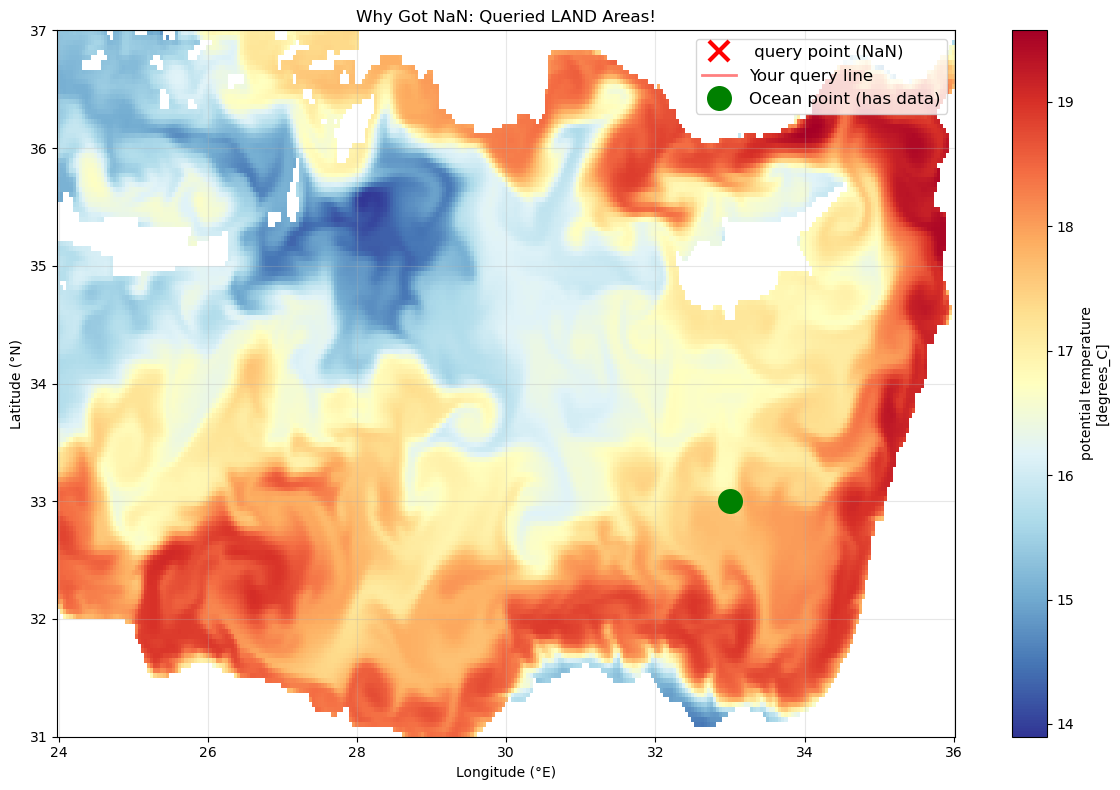

In [66]:
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset("processed_data/daily_chunks/daily_1993_01.nc")

# Get first day
temp = ds["temp_0_50m"].isel(time=0)

# Create map
fig, ax = plt.subplots(figsize=(12, 8))
temp.plot(ax=ax, cmap='RdYlBu_r')

# Mark the location you checked
ax.plot(29.0, 30.1875, 'rx', markersize=15, markeredgewidth=3, label=' query point (NaN)')
ax.plot([29.0, 29.8], [30.1875, 30.1875], 'r-', linewidth=2, alpha=0.5, label='Your query line')

# Mark an ocean point
ax.plot(33.0, 33.0, 'go', markersize=15, markeredgewidth=3, label='Ocean point (has data)')

ax.legend(fontsize=12)
ax.set_title('Why Got NaN: Queried LAND Areas!')
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()